# Company route choice and full-flight optimization

This example first chooses the lowest-fuel flight from six predefined company routes, then repeats the workflow for routes generated from a company waypoint network. Both sources produce `RouteOption` objects and use the same `top.optimize_routes()` call.

The AMS-FCO alternatives are illustrative rather than recorded tracks. Their distances are plausible relative to the **841-920 mile** range reported by [FlightPaths for AMS-FCO](https://www.flightpaths.com/AMS-FCO).

## Waypoint and time-step settings

Waypoint constraints use dimensionless distance divided by the stated tolerance; the tolerance remains a physical distance in metres. Each optimized time interval can vary from 1 to 600 seconds. Explicit bounds allow short route legs without forcing them to use a duration derived from the whole flight. These bounds are example settings and should be checked for other routes and meshes.

For `CompleteFlight`, departure and arrival headings follow the first and last route legs. The optimizer uses the same projected coordinates and heading convention as its dynamics. Flights without waypoints retain the direct airport-to-airport endpoint heading.


## 1. Define source-neutral route options

`RouteOption` is the boundary between a route provider and OpenTOP. A company catalogue can construct it directly; the RAD subsystem produces the same object after graph search. Origin and destination are included, while the intermediate points become ordered optimization constraints.

In [1]:
import warnings
from itertools import pairwise
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

import numpy as np
import opentop as top
import pandas as pd
from opentop.routes import route_initial_guess
from pyproj import Geod

warnings.filterwarnings("ignore", message=".*wave drag.*")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.22,
    }
)
COLORS = ("#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9")
GEOD = Geod(ellps="WGS84")

ROOT = Path.cwd()
if ROOT.name == "examples":
    ROOT = ROOT.parent
from opentop.plotting import (  # noqa: E402
    LINE_STYLES,
    MARKERS,
    apply_publication_style,
    plot_wind_vectors,
    style_map,
)

apply_publication_style()

In [2]:
AMS = (52.3086, 4.7639)
FCO = (41.8003, 12.2389)

routes = (
    top.RouteOption(
        "Company North",
        (AMS, (51.5, 7.2), (49.2, 8.0), (47.0, 10.8), (44.5, 11.0), FCO),
        metadata={"catalogue": "illustrative", "route_id": "NORTH-1"},
    ),
    top.RouteOption(
        "Company West",
        (AMS, (50.6, 3.7), (48.2, 5.5), (46.2, 7.5), (44.0, 9.8), FCO),
        metadata={"catalogue": "illustrative", "route_id": "WEST-1"},
    ),
    top.RouteOption(
        "Company East",
        (AMS, (51.0, 8.0), (49.2, 11.0), (47.0, 13.0), (44.5, 13.5), FCO),
        metadata={"catalogue": "illustrative", "route_id": "EAST-1"},
    ),
    top.RouteOption(
        "Company Central",
        (AMS, (50.7, 8.0), (48.5, 9.5), (46.2, 9.0), (43.8, 11.5), FCO),
        metadata={"catalogue": "illustrative", "route_id": "CENTRAL-1"},
    ),
    top.RouteOption(
        "Company Alpine",
        (AMS, (50.8, 3.8), (49.0, 4.5), (47.0, 6.0), (45.0, 7.5), (43.5, 10.2), FCO),
        metadata={"catalogue": "illustrative", "route_id": "ALPINE-1"},
    ),
    top.RouteOption(
        "Company Adriatic",
        (AMS, (51.1, 7.5), (49.5, 10.2), (47.5, 12.1), (45.5, 13.0), (43.5, 13.2), FCO),
        metadata={"catalogue": "illustrative", "route_id": "ADRIATIC-1"},
    ),
)

provided_routes = pd.DataFrame(
    {
        "route": [route.name for route in routes],
        "route_id": [route.metadata["route_id"] for route in routes],
        "waypoints": [len(route.waypoints) for route in routes],
        "distance_km": [route.distance_m / 1_000 for route in routes],
    }
).sort_values("distance_km")
provided_routes.round({"distance_km": 1})

,route,route_id,waypoints,distance_km
0,Company North,NORTH-1,6,1368.5
3,Company Central,CENTRAL-1,6,1375.1
1,Company West,WEST-1,6,1389.6
4,Company Alpine,ALPINE-1,7,1411.6
5,Company Adriatic,ADRIATIC-1,7,1417.3
2,Company East,EAST-1,6,1444.5


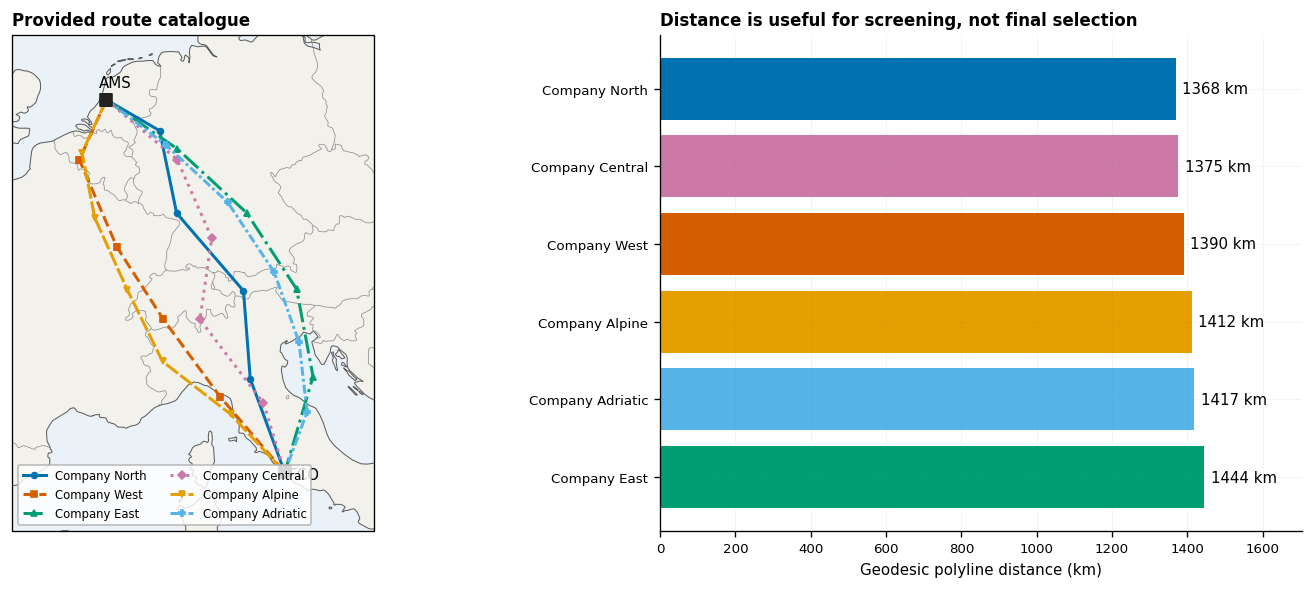

In [3]:
fig = plt.figure(figsize=(12, 4.8), constrained_layout=True)
ax_map = fig.add_subplot(1, 2, 1, projection=ccrs.LambertConformal(central_longitude=9))
ax_bar = fig.add_subplot(1, 2, 2)

ax_map.set_extent([2.0, 15.5, 40.0, 54.0], crs=ccrs.PlateCarree())
ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#f3f1ec")
ax_map.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="#eaf2f8")
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.45, edgecolor="0.55")
ax_map.coastlines(resolution="50m", linewidth=0.6, color="0.35")
for route, color, line_style, marker in zip(routes, COLORS, LINE_STYLES, MARKERS):
    latitudes, longitudes = zip(*route.waypoints)
    ax_map.plot(
        longitudes,
        latitudes,
        color=color,
        linestyle=line_style,
        marker=marker,
        linewidth=1.8,
        markersize=3.5,
        label=route.name,
        transform=ccrs.PlateCarree(),
    )
ax_map.scatter(
    [AMS[1], FCO[1]],
    [AMS[0], FCO[0]],
    s=45,
    marker="s",
    color="#222222",
    zorder=5,
    transform=ccrs.PlateCarree(),
)
ax_map.text(AMS[1] - 0.35, AMS[0] + 0.35, "AMS", transform=ccrs.PlateCarree())
ax_map.text(FCO[1] + 0.15, FCO[0] - 0.2, "FCO", transform=ccrs.PlateCarree())
ax_map.set_title("Provided route catalogue", loc="left", fontweight="bold")
ax_map.legend(loc="lower left", frameon=True, fontsize=7, ncol=2)

ordered = provided_routes.sort_values("distance_km", ascending=False)
color_by_name = dict(zip([route.name for route in routes], COLORS))
bars = ax_bar.barh(
    ordered.route,
    ordered.distance_km,
    color=[color_by_name[name] for name in ordered.route],
)
ax_bar.bar_label(bars, fmt="%.0f km", padding=4)
ax_bar.set_xlabel("Geodesic polyline distance (km)")
ax_bar.set_title(
    "Distance is useful for screening, not final selection",
    loc="left",
    fontweight="bold",
)
ax_bar.set_xlim(0, ordered.distance_km.max() * 1.18)
plt.show()

### Reproducible ERA5 wind

Both route stages use the same 4-D wind field. `build_route_wind_sample.py` contains the FastMeteo request and ERA5 conversion shared by the examples. The cell below loads the checked-in sample for a fast, offline run; set `REFRESH_FASTMETEO = True` to regenerate it through FastMeteo.

In [4]:
from runpy import run_path

WIND_HELPER = ROOT / "examples" / "data" / "build_route_wind_sample.py"
REFRESH_FASTMETEO = False

load_fastmeteo_wind_sample = run_path(str(WIND_HELPER))["load_fastmeteo_wind_sample"]
wind = load_fastmeteo_wind_sample(refresh=REFRESH_FASTMETEO)
print(f"Loaded {len(wind):,} FastMeteo/ERA5 wind samples")

Loaded 2,688 FastMeteo/ERA5 wind samples


## 2. Optimize every route with the public OpenTOP API

The factory returns a fresh wind-enabled `CompleteFlight` for every option. Ordered route points constrain the horizontal path, while altitude, Mach, vertical rate, timing, and mass remain continuous decision variables. The objective is fuel; no cost index is used.

In [5]:
def optimizer_factory():
    optimizer = top.CompleteFlight("A320", AMS, FCO, m0=0.85)
    optimizer.enable_wind(wind)
    return optimizer


optimization = top.RouteOptimizationConfig(
    objective="fuel",
    minimum_nodes=30,
    nodes_per_leg=2,
    waypoint_tolerance_m=15_000.0,
    trajectory_kwargs={"dt_min": 1, "dt_max": 600},
)
choice = top.optimize_routes(routes, optimizer_factory, config=optimization)

assert choice.best is not None
print(f"Selected: {choice.best.route.name}")
print(f"Optimized fuel: {choice.best.fuel_kg:,.0f} kg")

Selected: Company North
Optimized fuel: 4,944 kg


### Wind field used by the optimization

Blue arrows show the eastward and northward ERA5 components at FL350. The minimum-fuel route is orange; the other company options are retained in gray for context. Arrow length is quantitative and referenced by the 20 m/s key.

Text(0.5, 1.0, 'ERA5 wind at FL350 and optimized route: Company North - 1 May 2021, 08:00 UTC')

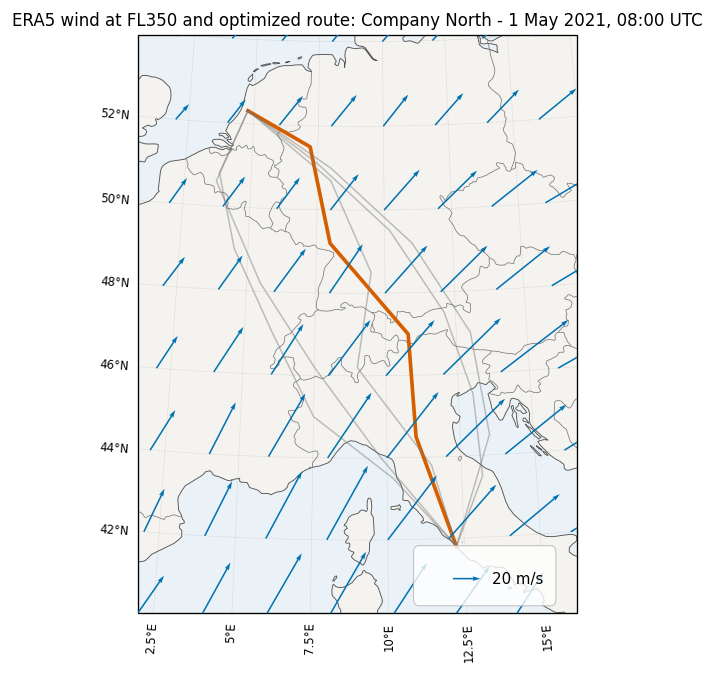

In [6]:
snapshot = wind.query("h == 10668 and ts == 0")

fig = plt.figure(figsize=(9.0, 5.5), constrained_layout=True)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.LambertConformal(central_longitude=9.0))
style_map(
    ax,
    extent=[2.0, 16.0, 40.0, 54.0],
    data_crs=ccrs.PlateCarree(),
    resolution="50m",
)

for route in routes:
    route_lats, route_lons = zip(*route.waypoints)
    color = "#D55E00" if route == choice.best.route else "#777777"
    width = 2.2 if route == choice.best.route else 0.9
    alpha = 1.0 if route == choice.best.route else 0.45
    ax.plot(
        route_lons,
        route_lats,
        color=color,
        linewidth=width,
        alpha=alpha,
        transform=ccrs.PlateCarree(),
        zorder=3,
    )

plot_wind_vectors(
    ax,
    snapshot,
    data_crs=ccrs.PlateCarree(),
    scale=320,
    width=0.0035,
    key_x=0.78,
)
ax.set_title(
    f"ERA5 wind at FL350 and optimized route: {choice.best.route.name} - "
    "1 May 2021, 08:00 UTC"
)

In [7]:
ranking = pd.DataFrame(
    {
        "route": [item.route.name for item in choice.optimized],
        "success": [item.success for item in choice.optimized],
        "fuel_kg": [item.fuel_kg for item in choice.optimized],
        "solve_s": choice.solve_seconds,
        "distance_km": [item.route.distance_m / 1_000 for item in choice.optimized],
        "status": [item.status for item in choice.optimized],
    }
).sort_values("fuel_kg")
ranking.round({"fuel_kg": 1, "solve_s": 1, "distance_km": 1})

,route,success,fuel_kg,solve_s,distance_km,status
0,Company North,True,4944.1,47.7,1368.5,Solve_Succeeded
3,Company Central,True,4962.7,54.9,1375.1,Solve_Succeeded
1,Company West,True,4998.4,46.7,1389.6,Solve_Succeeded
4,Company Alpine,True,5054.7,52.3,1411.6,Solve_Succeeded
5,Company Adriatic,True,5107.5,63.8,1417.3,Solve_Succeeded
2,Company East,True,5196.6,37.9,1444.5,Solve_Succeeded


The ranking above is based on the fuel from the nonlinear aircraft-performance optimization. A graph or catalogue can rank by distance first to reduce the candidate count, but distance is not substituted for the final fuel comparison.

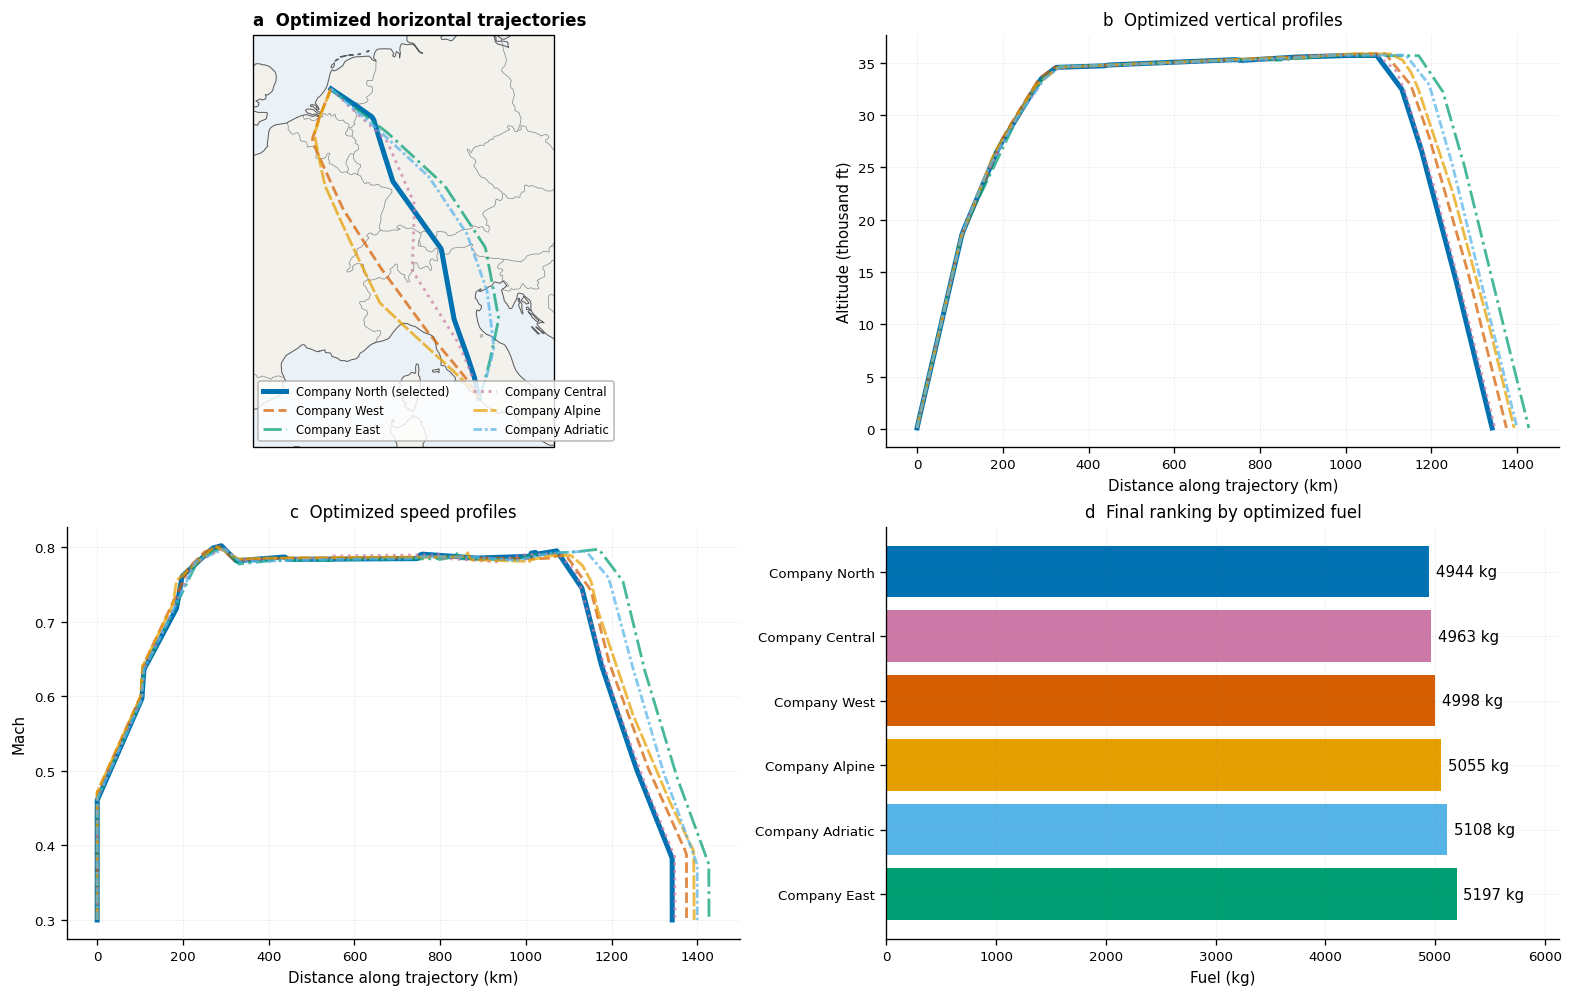

In [8]:
def cumulative_distance_km(trajectory):
    distances = [0.0]
    points = list(zip(trajectory.latitude, trajectory.longitude))
    for (lat_a, lon_a), (lat_b, lon_b) in pairwise(points):
        distances.append(GEOD.inv(lon_a, lat_a, lon_b, lat_b)[2] / 1_000)
    return np.cumsum(distances)


fig = plt.figure(figsize=(13, 8.2), constrained_layout=True)
ax_map = fig.add_subplot(2, 2, 1, projection=ccrs.LambertConformal(central_longitude=9))
ax_alt = fig.add_subplot(2, 2, 2)
ax_mach = fig.add_subplot(2, 2, 3)
ax_fuel = fig.add_subplot(2, 2, 4)

ax_map.set_extent([2.0, 15.5, 40.0, 54.0], crs=ccrs.PlateCarree())
ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#f3f1ec")
ax_map.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="#eaf2f8")
ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.45, edgecolor="0.55")
ax_map.coastlines(resolution="50m", linewidth=0.6, color="0.35")

for item, color, line_style in zip(choice.optimized, COLORS, LINE_STYLES):
    if not item.success:
        continue
    trajectory = item.trajectory
    distance = cumulative_distance_km(trajectory)
    selected = item is choice.best
    linewidth = 3.0 if selected else 1.7
    alpha = 1.0 if selected else 0.72
    label = item.route.name + (" (selected)" if selected else "")
    ax_map.plot(
        trajectory.longitude,
        trajectory.latitude,
        color=color,
        linestyle=line_style,
        linewidth=linewidth,
        alpha=alpha,
        label=label,
        transform=ccrs.PlateCarree(),
    )
    ax_alt.plot(
        distance,
        trajectory.altitude / 1_000,
        color=color,
        linestyle=line_style,
        linewidth=linewidth,
        alpha=alpha,
        label=label,
    )
    ax_mach.plot(
        distance,
        trajectory.mach,
        color=color,
        linestyle=line_style,
        linewidth=linewidth,
        alpha=alpha,
        label=label,
    )

ax_map.set_title("a  Optimized horizontal trajectories", loc="left", fontweight="bold")
ax_map.legend(loc="lower left", fontsize=7, frameon=True, ncol=2)
ax_alt.set(
    title="b  Optimized vertical profiles",
    xlabel="Distance along trajectory (km)",
    ylabel="Altitude (thousand ft)",
)
ax_mach.set(
    title="c  Optimized speed profiles",
    xlabel="Distance along trajectory (km)",
    ylabel="Mach",
)

fuel_order = ranking.sort_values("fuel_kg", ascending=False)
bars = ax_fuel.barh(
    fuel_order.route,
    fuel_order.fuel_kg,
    color=[color_by_name[name] for name in fuel_order.route],
)
ax_fuel.bar_label(bars, fmt="%.0f kg", padding=4)
ax_fuel.set(title="d  Final ranking by optimized fuel", xlabel="Fuel (kg)")
ax_fuel.set_xlim(0, fuel_order.fuel_kg.max() * 1.18)
plt.show()

## 3. What the shared implementation does internally

For each option, the common implementation performs four steps:

1. Use the interior points as ordered waypoint constraints.
2. Choose a mesh size from the route's number of legs.
3. Build a route-shaped initial guess, including climb and descent for `CompleteFlight`.
4. Solve with a fresh optimizer and validate that the result visits the waypoints in order.

Candidate failures are stored with their status, so one infeasible route does not discard the others.

In [9]:
example_route = routes[0]
example_guess = route_initial_guess(
    example_route,
    nodes=30,
    altitude_ft=35_000.0,
    mass_kg=60_000.0,
    complete_flight=True,
)

pd.DataFrame(
    {
        "item": ["polyline points", "interior constraints", "mesh states"],
        "count": [
            len(example_route.waypoints),
            len(example_route.interior_waypoints),
            len(example_guess),
        ],
    }
)

,item,count
0,polyline points,6
1,interior constraints,4
2,mesh states,31


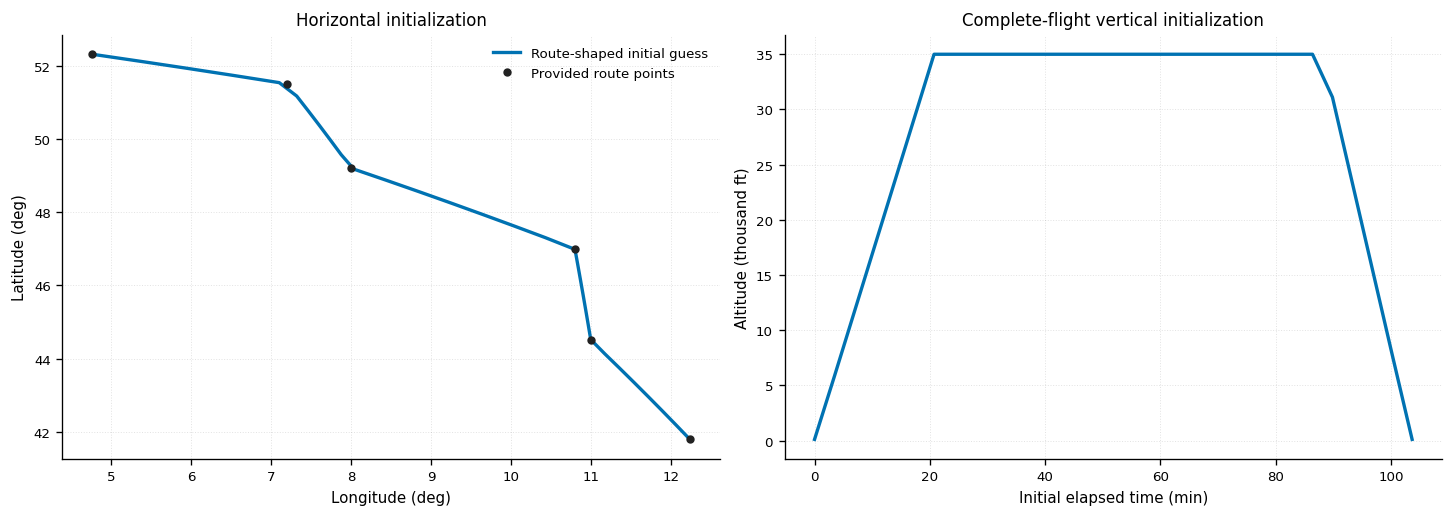

In [10]:
fig, (ax_path, ax_profile) = plt.subplots(
    1, 2, figsize=(12, 4.2), constrained_layout=True
)
route_lats, route_lons = zip(*example_route.waypoints)
ax_path.plot(
    example_guess.longitude,
    example_guess.latitude,
    color=COLORS[0],
    linewidth=2,
    label="Route-shaped initial guess",
)
ax_path.plot(
    route_lons,
    route_lats,
    "o",
    color="#222222",
    markersize=4,
    label="Provided route points",
)
ax_path.set(
    xlabel="Longitude (deg)", ylabel="Latitude (deg)", title="Horizontal initialization"
)
ax_path.legend(frameon=False)
ax_profile.plot(
    example_guess.ts / 60, example_guess.altitude / 1_000, color=COLORS[0], linewidth=2
)
ax_profile.set(
    xlabel="Initial elapsed time (min)",
    ylabel="Altitude (thousand ft)",
    title="Complete-flight vertical initialization",
)
plt.show()

## 4. Construct routes from a company waypoint network

A set of waypoint coordinates alone does not define which legs are operationally permitted. `RouteNetwork` therefore takes both named waypoints and directed connections. It uses the same A*/Yen candidate search and diversity filtering as RAD, but has no RAD parsing or availability rules. The result again exposes `selection.options`, ready for the same `optimize_routes` call.

In [11]:
company_waypoints = {
    "AMS": AMS,
    "W1": (50.6, 3.7),
    "W2": (48.2, 5.5),
    "W3": (46.2, 7.5),
    "W4": (44.0, 9.8),
    "N1": (51.5, 7.2),
    "N2": (49.2, 8.0),
    "N3": (47.0, 10.8),
    "N4": (44.5, 11.0),
    "E1": (51.0, 8.0),
    "E2": (49.2, 11.0),
    "E3": (47.0, 13.0),
    "E4": (44.5, 13.5),
    "C1": (50.7, 8.0),
    "C2": (48.5, 9.5),
    "C3": (46.2, 9.0),
    "C4": (43.8, 11.5),
    "FCO": FCO,
}
company_connections = (
    ("AMS", "W1"),
    ("AMS", "N1"),
    ("AMS", "C1"),
    ("AMS", "E1"),
    ("W1", "W2"),
    ("W1", "N2"),
    ("N1", "N2"),
    ("N1", "C2"),
    ("C1", "C2"),
    ("C1", "E2"),
    ("E1", "E2"),
    ("E1", "C2"),
    ("W2", "W3"),
    ("W2", "C3"),
    ("N2", "N3"),
    ("N2", "C3"),
    ("C2", "C3"),
    ("C2", "N3"),
    ("C2", "E3"),
    ("E2", "E3"),
    ("E2", "N3"),
    ("W3", "W4"),
    ("W3", "C4"),
    ("C3", "C4"),
    ("C3", "W4"),
    ("C3", "N4"),
    ("N3", "N4"),
    ("N3", "C4"),
    ("E3", "E4"),
    ("E3", "C4"),
    ("W4", "FCO"),
    ("N4", "FCO"),
    ("C4", "FCO"),
    ("E4", "FCO"),
)

In [12]:
company_network = top.RouteNetwork.from_connections(
    company_waypoints, company_connections
)
network_selection = company_network.select_routes(
    "AMS",
    "FCO",
    config=top.RouteSelectionConfig(
        candidates=5,
        search_candidates=100,
        max_cost_ratio=1.30,
        max_distance_ratio=1.30,
        maximum_shared_edge_fraction=0.30,
    ),
)

network_candidates = pd.DataFrame(
    {
        "route": [option.name for option in network_selection.options],
        "nodes": [
            " -> ".join(option.metadata["node_ids"])
            for option in network_selection.options
        ],
        "distance_km": [path.distance_m / 1_000 for path in network_selection.paths],
    }
)
network_candidates.round({"distance_km": 1})

,route,nodes,distance_km
0,Network route 1,AMS -> C1 -> C2 -> N3 -> C4 -> FCO,1338.1
1,Network route 2,AMS -> N1 -> C2 -> N3 -> N4 -> FCO,1350.3
2,Network route 3,AMS -> N1 -> N2 -> C3 -> C4 -> FCO,1356.1
3,Network route 4,AMS -> E1 -> C2 -> C3 -> N4 -> FCO,1385.7
4,Network route 5,AMS -> W1 -> W2 -> W3 -> W4 -> FCO,1389.6


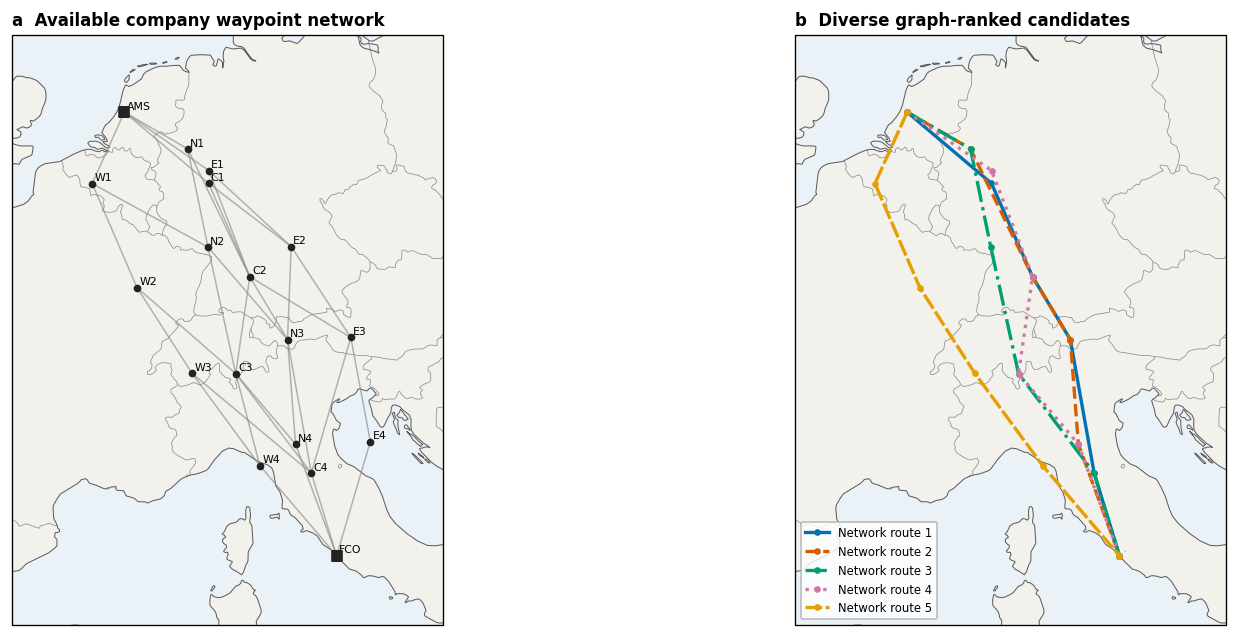

In [13]:
def style_route_map(ax, title):
    ax.set_extent([2.0, 15.5, 40.0, 54.0], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#f3f1ec")
    ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="#eaf2f8")
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.45, edgecolor="0.55")
    ax.coastlines(resolution="50m", linewidth=0.6, color="0.35")
    ax.set_title(title, loc="left", fontweight="bold")


fig = plt.figure(figsize=(13, 5.2), constrained_layout=True)
ax_network = fig.add_subplot(
    1, 2, 1, projection=ccrs.LambertConformal(central_longitude=9)
)
ax_candidates = fig.add_subplot(
    1, 2, 2, projection=ccrs.LambertConformal(central_longitude=9)
)
style_route_map(ax_network, "a  Available company waypoint network")
style_route_map(ax_candidates, "b  Diverse graph-ranked candidates")

for edge in company_network.graph.edges.values():
    source = company_network.graph.nodes[edge.source]
    target = company_network.graph.nodes[edge.target]
    ax_network.plot(
        [source.longitude, target.longitude],
        [source.latitude, target.latitude],
        color="#8c8c8c",
        linewidth=0.9,
        alpha=0.65,
        transform=ccrs.PlateCarree(),
    )
for waypoint_id, (latitude, longitude) in company_network.waypoints.items():
    endpoint = waypoint_id in {"AMS", "FCO"}
    ax_network.scatter(
        longitude,
        latitude,
        s=34 if endpoint else 13,
        marker="s" if endpoint else "o",
        color="#222222",
        zorder=5,
        transform=ccrs.PlateCarree(),
    )
    ax_network.text(
        longitude + 0.08,
        latitude + 0.08,
        waypoint_id,
        fontsize=6.5,
        transform=ccrs.PlateCarree(),
    )

for option, color, line_style in zip(network_selection.options, COLORS, LINE_STYLES):
    latitudes, longitudes = zip(*option.waypoints)
    ax_candidates.plot(
        longitudes,
        latitudes,
        color=color,
        linestyle=line_style,
        linewidth=2.0,
        marker="o",
        markersize=3,
        label=option.name,
        transform=ccrs.PlateCarree(),
    )
ax_candidates.legend(loc="lower left", fontsize=7, frameon=True)
plt.show()

The graph score above is distance, used only to avoid solving every possible waypoint combination. The retained polylines now cross the same `RouteOption` boundary as the predefined catalogue and RAD candidates. We optimize all five with exactly the same aircraft factory and `RouteOptimizationConfig`.

In [14]:
network_choice = top.optimize_routes(
    network_selection.options,
    optimizer_factory,
    config=optimization,
)
assert network_choice.best is not None

network_ranking = pd.DataFrame(
    {
        "route": [item.route.name for item in network_choice.optimized],
        "nodes": [
            " -> ".join(item.route.metadata["node_ids"])
            for item in network_choice.optimized
        ],
        "distance_km": [
            item.route.distance_m / 1_000 for item in network_choice.optimized
        ],
        "fuel_kg": [item.fuel_kg for item in network_choice.optimized],
        "solve_s": network_choice.solve_seconds,
        "success": [item.success for item in network_choice.optimized],
    }
).sort_values("fuel_kg")
print(f"Selected network path: {network_choice.best.route.name}")
network_ranking.round({"distance_km": 1, "fuel_kg": 1, "solve_s": 1})

Selected network path: Network route 1


,route,nodes,distance_km,fuel_kg,solve_s,success
0,Network route 1,AMS -> C1 -> C2 -> N3 -> C4 -> FCO,1338.1,4895.3,51.1,True
1,Network route 2,AMS -> N1 -> C2 -> N3 -> N4 -> FCO,1350.3,4923.4,58.9,True
2,Network route 3,AMS -> N1 -> N2 -> C3 -> C4 -> FCO,1356.1,4925.9,50.7,True
3,Network route 4,AMS -> E1 -> C2 -> C3 -> N4 -> FCO,1385.7,4994.8,53.2,True
4,Network route 5,AMS -> W1 -> W2 -> W3 -> W4 -> FCO,1389.6,4998.4,45.3,True


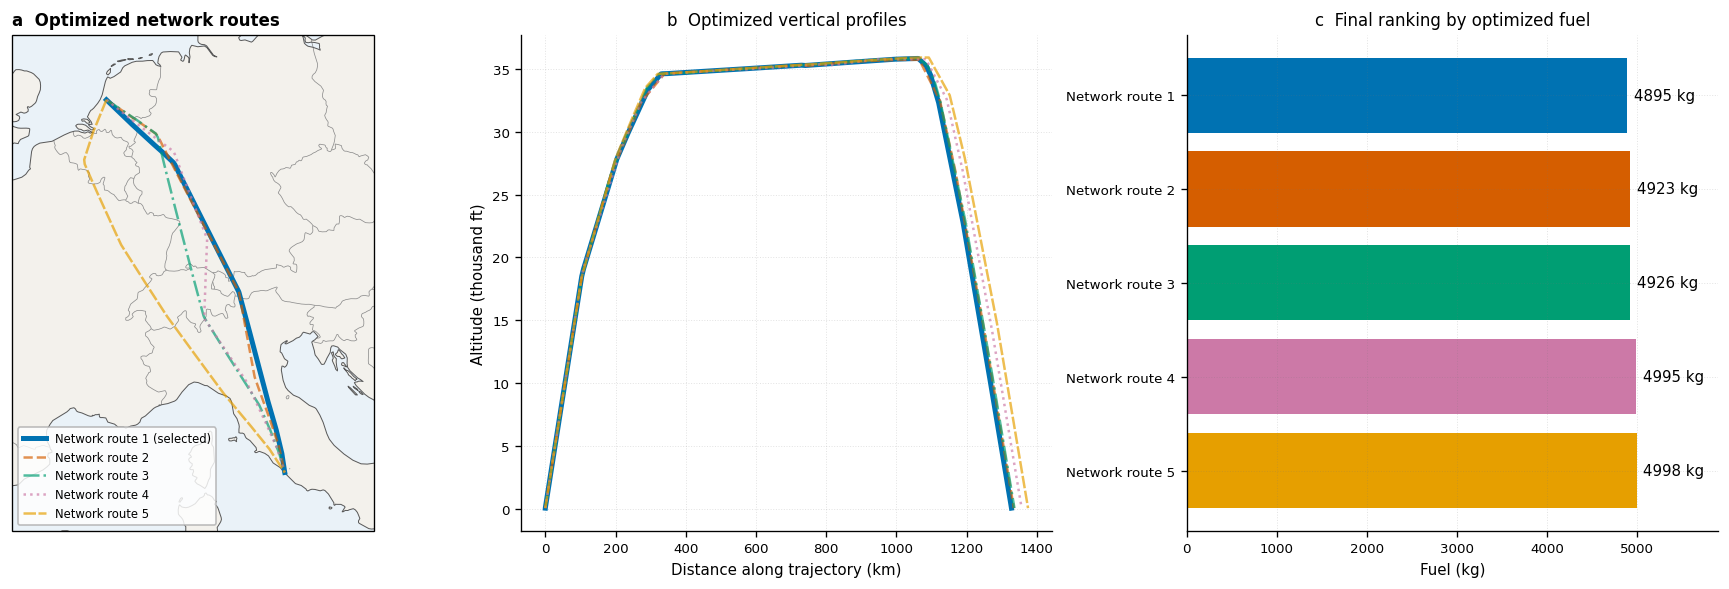

In [15]:
fig = plt.figure(figsize=(15, 4.8), constrained_layout=True)
ax_map = fig.add_subplot(1, 3, 1, projection=ccrs.LambertConformal(central_longitude=9))
ax_altitude = fig.add_subplot(1, 3, 2)
ax_fuel = fig.add_subplot(1, 3, 3)
style_route_map(ax_map, "a  Optimized network routes")

for item, color, line_style in zip(network_choice.optimized, COLORS, LINE_STYLES):
    if not item.success:
        continue
    selected = item is network_choice.best
    linewidth = 3.0 if selected else 1.5
    alpha = 1.0 if selected else 0.68
    label = item.route.name + (" (selected)" if selected else "")
    trajectory = item.trajectory
    distance = cumulative_distance_km(trajectory)
    ax_map.plot(
        trajectory.longitude,
        trajectory.latitude,
        color=color,
        linestyle=line_style,
        linewidth=linewidth,
        alpha=alpha,
        label=label,
        transform=ccrs.PlateCarree(),
    )
    ax_altitude.plot(
        distance,
        trajectory.altitude / 1_000,
        color=color,
        linestyle=line_style,
        linewidth=linewidth,
        alpha=alpha,
        label=label,
    )
ax_map.legend(loc="lower left", fontsize=7, frameon=True)
ax_altitude.set(
    title="b  Optimized vertical profiles",
    xlabel="Distance along trajectory (km)",
    ylabel="Altitude (thousand ft)",
)
network_fuel_order = network_ranking.sort_values("fuel_kg", ascending=False)
bars = ax_fuel.barh(
    network_fuel_order.route,
    network_fuel_order.fuel_kg,
    color=[
        COLORS[int(name.rsplit(" ", 1)[1]) - 1] for name in network_fuel_order.route
    ],
)
ax_fuel.bar_label(bars, fmt="%.0f kg", padding=4)
ax_fuel.set(title="c  Final ranking by optimized fuel", xlabel="Fuel (kg)")
ax_fuel.set_xlim(0, network_fuel_order.fuel_kg.max() * 1.18)
plt.show()

## 5. How RAD shares the same route optimizer

RAD has additional source-specific responsibilities: parse AIRAC files, apply flight-level and availability rules, build the directed graph, and search for diverse paths. It stops at the same `RouteOption` boundary:

```python
selection = dataset.select_routes(context)
assert all(isinstance(option, top.RouteOption) for option in selection.options)

choice = top.optimize_routes(
    selection.options, optimizer_factory, config=optimization
)
```

The workflow is identical for both searchable sources: `selection = source.select_routes(...)`, followed by `top.optimize_routes(selection.options, ..., config=...)`. Predefined catalogues skip only the search stage because they already are `RouteOption` objects. There is intentionally no RAD-specific continuous optimization method.

## Takeaways

- Route identity is a discrete choice: each retained option gets an independent wind-enabled NLP solve.
- Predefined catalogues, company waypoint networks, and RAD all meet at `RouteOption` and `top.optimize_routes()`.
- `CompleteFlight` jointly optimizes speed and the climb/cruise/descent profile for each route.
- The winner is the lowest-fuel successful trajectory, not necessarily the shortest route or cheapest graph-screening result.